<a href="https://colab.research.google.com/github/faryalkalwar66/ML_LAB_Assignments/blob/main/Lab10_KMeans_Clustering_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:Faryal**
- **Student ID:023-24-0079**
- **Section:D**
- **GitHub:https://github.com/faryalkalwar66/ML_LAB_Assignments**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [4]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [5]:
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)':'Income', 'Spending Score (1-100)':'Spending'})
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df['Gender'].value_counts())
df[['Age','Income','Spending']].describe()


Shape: (200, 5)
Missing values: 0
Duplicate rows: 0
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


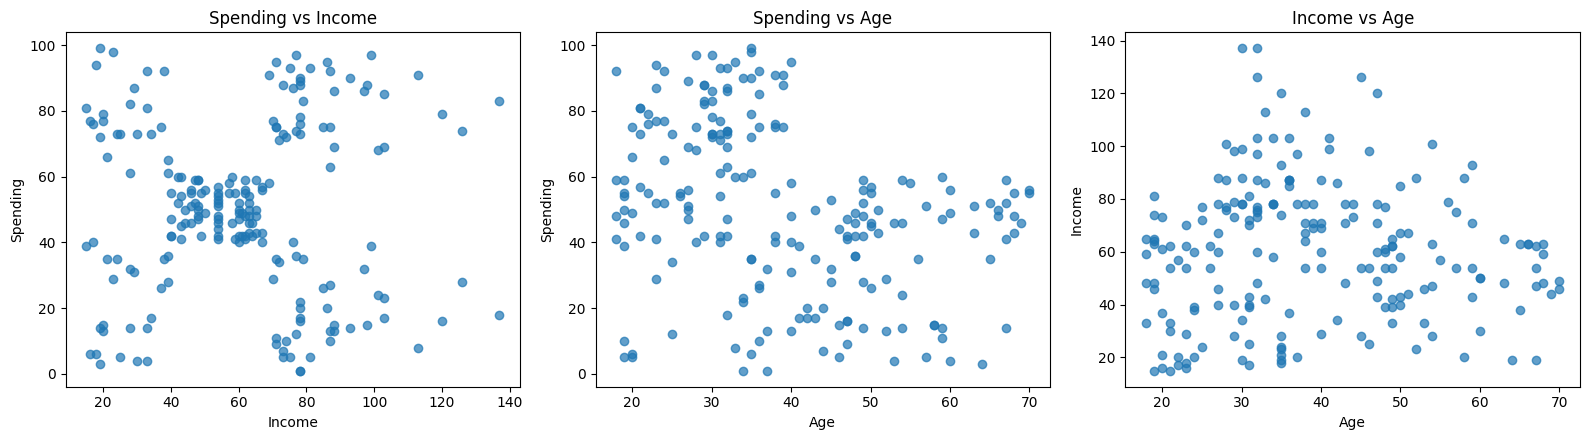

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
pairs = [('Income','Spending'), ('Age','Spending'), ('Age','Income')]
for a, (x, y) in zip(ax, pairs):
    a.scatter(df[x], df[y], alpha=0.7)
    a.set_xlabel(x); a.set_ylabel(y); a.set_title(f'{y} vs {x}')
plt.tight_layout(); plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



(a) Spending vs Income mein saaf 5 groups dikhte hain: low/low, low income/high spending, mid/mid (beech mein bada group), high income/low spending, high/high. Yeh sabse clear plot hai. Spending vs Age mein koi clear group nahi hai, sirf ek pattern hai ke 40 se zyada umar ke log high spending kam karte hain. Income vs Age mein bhi koi group nahi dikhta, points bikhre hue hain.
(b) Data mein koi target ya “sahi jawab” column nahi hai, to predicted label ko compare karne ke liye kuch hai hi nahi, is liye accuracy ban hi nahi sakti. Train/test split ka bhi faida nahi, kyunke seekhne ke liye labels chahiye hi nahi. Clustering ko distance, silhouette, plots aur common sense se judge karte hain.

---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [7]:
x = np.array([2,4,10,12,3,20,30,11,25], dtype=float)
m = np.array([4., 11.])
for it in range(1, 20):
    dist = np.abs(x[:, None] - m[None, :])          # (9,2)
    labels = dist.argmin(axis=1)
    new_m = np.array([x[labels==k].mean() for k in range(2)])
    print(f"Iter {it}: C1={x[labels==0]}  C2={x[labels==1]}  centroids={new_m}")
    if np.allclose(new_m, m): break
    m = new_m
inertia = sum(((x[labels==k] - m[k])**2).sum() for k in range(2))
print("Final centroids:", m, " Inertia:", inertia)


Iter 1: C1=[2. 4. 3.]  C2=[10. 12. 20. 30. 11. 25.]  centroids=[ 3. 18.]
Iter 2: C1=[ 2.  4. 10.  3.]  C2=[12. 20. 30. 11. 25.]  centroids=[ 4.75 19.6 ]
Iter 3: C1=[ 2.  4. 10. 12.  3. 11.]  C2=[20. 30. 25.]  centroids=[ 7. 25.]
Iter 4: C1=[ 2.  4. 10. 12.  3. 11.]  C2=[20. 30. 25.]  centroids=[ 7. 25.]
Final centroids: [ 7. 25.]  Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [8]:
X = np.array([[185,72],[170,56],[168,60],[179,68],[182,72],[188,77]], dtype=float)
C = X[[0,1]].copy()
for it in range(1, 20):
    d = np.sqrt(((X[:, None, :] - C[None, :, :])**2).sum(axis=2))
    labels = d.argmin(axis=1)
    new_C = np.array([X[labels==k].mean(axis=0) for k in range(2)])
    print(f"Iter {it}: clusters={labels+1}\n centroids=\n{new_C.round(2)}")
    if np.allclose(new_C, C): break
    C = new_C
print(d.round(2))
print(np.sqrt((168-170)**2 + (60-56)**2))


Iter 1: clusters=[1 2 2 1 1 1]
 centroids=
[[183.5   72.25]
 [169.    58.  ]]
Iter 2: clusters=[1 2 2 1 1 1]
 centroids=
[[183.5   72.25]
 [169.    58.  ]]
[[ 1.52 21.26]
 [21.13  2.24]
 [19.76  2.24]
 [ 6.19 14.14]
 [ 1.52 19.1 ]
 [ 6.54 26.87]]
4.47213595499958


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [9]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, float)
    C = np.asarray(init_centroids, float).copy()
    if X.ndim == 1: X = X[:, None]
    if C.ndim == 1: C = C[:, None]
    for it in range(1, max_iter + 1):
        d = np.sqrt(((X[:, None, :] - C[None, :, :])**2).sum(axis=2))
        labels = d.argmin(axis=1)
        new_C = C.copy()
        for k in range(len(C)):
            if (labels == k).any():
                new_C[k] = X[labels == k].mean(axis=0)
        if np.allclose(new_C, C): break
        C = new_C
    d = np.sqrt(((X[:, None, :] - C[None, :, :])**2).sum(axis=2))
    labels = d.argmin(axis=1)
    inertia = (d.min(axis=1)**2).sum()
    return labels, C, inertia, it

In [10]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
lab, cen, inert, n = my_kmeans(x, [4, 11])
print("Labels    :", lab)
print("Centroids :", cen.ravel())
print("Inertia   :", inert)
print("Iterations:", n)


Labels    : [0 0 0 0 0 1 1 0 1]
Centroids : [ 7. 25.]
Inertia   : 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [11]:
X2 = df[['Income', 'Spending']].values.astype(float)
init = X2[:5]
lab_my, cen_my, inert_my, n_my = my_kmeans(X2, init)

km = KMeans(n_clusters=5, init=init, n_init=1, tol=0, algorithm='lloyd').fit(X2)

print("Iterations     : mine =", n_my, "| sklearn =", km.n_iter_)
print("Inertia        : mine =", round(inert_my, 3), "| sklearn =", round(km.inertia_, 3))
print("Labels same    :", (lab_my == km.labels_).all())
print("Centroids same :", np.allclose(cen_my, km.cluster_centers_))

print("\nMy centroids:\n", cen_my.round(2))
print("\nsklearn centroids:\n", km.cluster_centers_.round(2))


Iterations     : mine = 4 | sklearn = 4
Inertia        : mine = 44448.455 | sklearn = 44448.455
Labels same    : True
Centroids same : True

My centroids:
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]

sklearn centroids:
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



(a) In iteration 1 the starting centroids were 4 and 11. The point 10 was closer to 11 (distance 1) than to 4 (distance 6), so it went to C2. After the update step the centroids moved to 3 (C1 = {2, 4, 3}) and 18 (C2 = {10, 12, 20, 30, 11, 25}). In iteration 2 the distance from 10 to C1 is |10 − 3| = 7 and to C2 is |10 − 18| = 8. Now C1 is closer, so 10 moved to C1. The cause is that C2’s centroid was pulled from 11 up to 18 by the large values 20, 30 and 25, which made it farther from 10.

(b) The loop stops when the assign step gives the same clusters as before, so no point changes cluster and the centroids stop moving. In Example 1 this happened in iteration 4, with centroids 7 and 25. Stopping is guaranteed because each assign step and each update step can only lower the inertia or keep it the same. There is also only a finite number of ways to split the points into clusters, so the inertia cannot keep dropping forever. It must settle at a point where nothing improves. That point is only a local minimum, so it depends on the starting centroids. A different start can end at a different, possibly better, solution. That is why stopping is guaranteed but the best answer is not.

(c) Yes, it matched exactly. Both ran 4 iterations and reached the same inertia (44448.46). The labels and the five centroids were identical. The reason is that both used the same starting centroids (first 5 rows of X2), n_init=1, tol=0 and algorithm='lloyd', which is the same assign/update loop I wrote. With default settings (k-means++, n_init=10), scikit-learn could start elsewhere and reach a different local minimum.

(d) A centroid is the average customer of a group. For example, one of my clusters has centroid (Income 88.2, Spending 17.11), which describes a high-income, low-spending group. It is a point in feature space, so it does not have to be a real customer in the data. K-Means needs numeric features because it computes distances (square, add, square root) to assign points and means to update centroids. Both operations are meaningless for text such as “Male” or “Female”. Categorical columns have to be encoded as numbers first, or left out.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K   Inertia  Silhouette
 2 181363.60      0.2969
 3 106348.37      0.4676
 4  73679.79      0.4932
 5  44448.46      0.5539
 6  37233.81      0.5398
 7  30241.34      0.5288
 8  25036.42      0.4548
 9  21916.79      0.4561
10  20072.07      0.4411


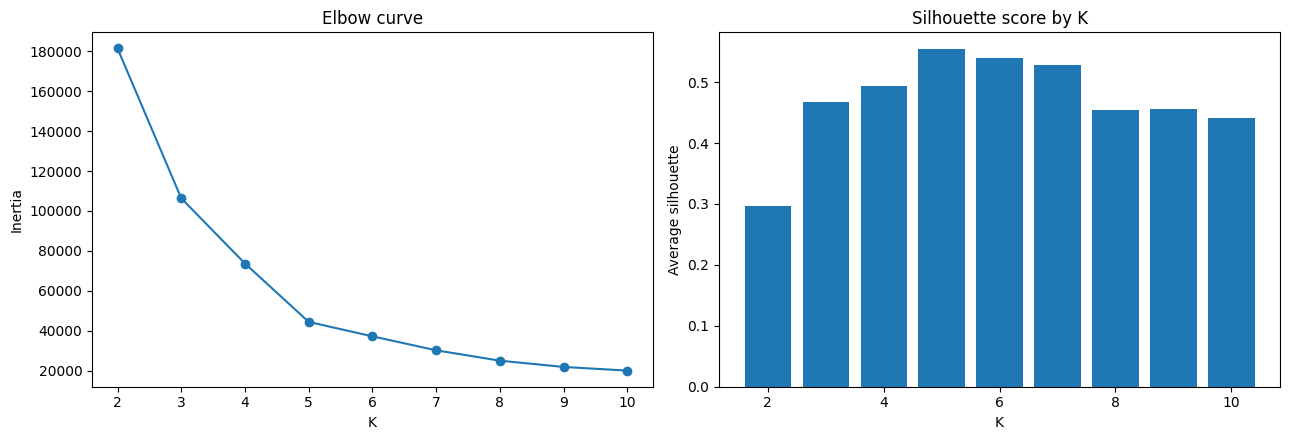

K with highest silhouette: 5


In [12]:
Ks = range(2, 11)
inertias, sils = [], []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X2, km.labels_))

res = pd.DataFrame({'K': list(Ks), 'Inertia': np.round(inertias, 2), 'Silhouette': np.round(sils, 4)})
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(list(Ks), inertias, marker='o')
ax[0].set_xlabel('K'); ax[0].set_ylabel('Inertia'); ax[0].set_title('Elbow curve')
ax[1].bar(list(Ks), sils)
ax[1].set_xlabel('K'); ax[1].set_ylabel('Average silhouette'); ax[1].set_title('Silhouette score by K')
plt.tight_layout(); plt.show()

best_k = list(Ks)[int(np.argmax(sils))]
print("K with highest silhouette:", best_k)

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [13]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
labels5 = km5.labels_

def silhouette_one(X, labels, i):
    d = np.sqrt(((X - X[i])**2).sum(axis=1))
    own = labels[i]
    same = (labels == own)
    same[i] = False
    a = d[same].mean()
    b = min(d[labels == k].mean() for k in np.unique(labels) if k != own)
    s = (b - a) / max(a, b)
    return a, b, s

a, b, s = silhouette_one(X2, labels5, 0)
sil = silhouette_samples(X2, labels5)
print(f"Customer 1 -> cluster {labels5[0]}")
print(f"a = {a:.4f}, b = {b:.4f}, s (mine) = {s:.4f}")
print(f"s (silhouette_samples) = {sil[0]:.4f}")


Customer 1 -> cluster 4
a = 24.6404, b = 42.2653, s (mine) = 0.4170
s (silhouette_samples) = 0.4170


         Count    Mean     Min
Cluster                       
0           81  0.5967  0.1153
1           39  0.5092  0.2254
2           22  0.5990  0.0507
3           35  0.5040 -0.0234
4           23  0.5123 -0.0093
Customers with negative silhouette: 2


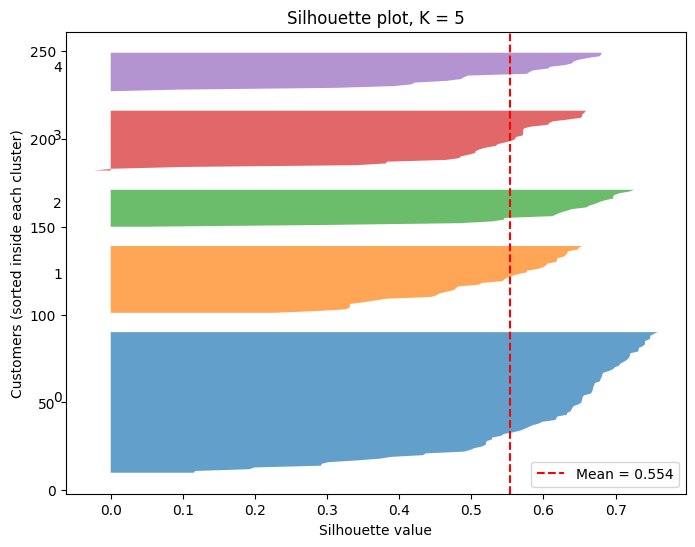

In [14]:
stats = (pd.DataFrame({'Cluster': labels5, 's': sil})
           .groupby('Cluster')['s'].agg(Count='count', Mean='mean', Min='min'))
print(stats.round(4))
print("Customers with negative silhouette:", (sil < 0).sum())

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
for k in range(5):
    sk = np.sort(sil[labels5 == k])
    y_upper = y_lower + len(sk)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, sk, alpha=0.7)
    ax.text(-0.08, y_lower + 0.5 * len(sk), str(k))
    y_lower = y_upper + 10
ax.axvline(sil.mean(), color='red', linestyle='--', label=f'Mean = {sil.mean():.3f}')
ax.set_xlabel('Silhouette value'); ax.set_ylabel('Customers (sorted inside each cluster)')
ax.set_title('Silhouette plot, K = 5'); ax.legend()
plt.show()


### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [15]:
p = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
P = p.reshape(-1, 1)
lab, cen, inert, n = my_kmeans(P, [1, 11])
print("Labels     :", lab)
print("Cluster 0  :", p[lab == 0], "| Cluster 1:", p[lab == 1])
print("Centroids  :", cen.ravel())
print("Inertia    :", inert)
print("Iterations :", n)

ss = silhouette_samples(P, lab)
for v in [1, 7, 11]:
    i = int(np.where(p == v)[0][0])
    a, b, s = silhouette_one(P, lab, i)
    print(f"Point {v:>2}: a = {a:.3f}, b = {b:.3f}, s (mine) = {s:.4f}, s (sklearn) = {ss[i]:.4f}")


Labels     : [0 0 0 0 1 1 1]
Cluster 0  : [1. 3. 5. 7.] | Cluster 1: [11. 13. 15.]
Centroids  : [ 4. 13.]
Inertia    : 28.0
Iterations : 3
Point  1: a = 4.000, b = 12.000, s (mine) = 0.6667, s (sklearn) = 0.6667
Point  7: a = 4.000, b = 6.000, s (mine) = 0.3333, s (sklearn) = 0.3333
Point 11: a = 3.000, b = 7.000, s (mine) = 0.5714, s (sklearn) = 0.5714


## **Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



(a) The elbow suggests K = 5. Inertia falls from 73,679.79 at K = 4 to 44,448.46 at K = 5, a drop of about 29,231. From K = 5 to K = 6 it falls only to 37,233.81, a drop of about 7,215, and later drops are even smaller (about 6,992 from 6 to 7). So the curve bends sharply at 5. The silhouette also suggests K = 5, where it is highest at 0.5539. It is lower at K = 4 (0.4932) and at K = 6 (0.5398). Both methods agree, and they match the 5 groups visible in the Income vs Spending scatter plot.

(b) Customer 1 (Income 15, Spending 39) has a silhouette of 0.4170 (a = 24.64, b = 42.27). It is positive and well above zero, so the customer is placed in the right cluster (cluster 4, low income / low spending). It is not a perfect fit, because the value is not close to 1. The weakest average silhouette belongs to cluster 3 (high income / low spending, 35 customers) at 0.5040. 2 customers have a negative silhouette: one in cluster 3 (−0.0234) and one in cluster 4 (−0.0093). Both are very close to zero, so they sit on the border between clusters.

(c) Point 7 is less well placed. For point 1, a = 4 (average distance to 3, 5, 7) and b = 12 (average distance to 11, 13, 15), so s = (12 − 4)/12 = 0.667. For point 7, a = 4 as well, but b is only 6, because 7 is close to the other cluster (11, 13, 15). So s = (6 − 4)/6 = 0.333. The gap between a and b is much smaller for point 7, which means it lies near the border of the two clusters.

(d) Inertia always decreases as K increases, because more centroids mean every point is closer to its own centroid. In my table it fell from 181,363.60 at K = 2 to 20,072.07 at K = 10. If we picked the lowest inertia, we would always pick the largest K. In the extreme, K = 200 (one cluster per customer) gives inertia 0, which is useless because it finds no groups at all. K must be chosen where the drop becomes small (the elbow) and where the silhouette is highest, so that the clusters are both compact and well separated. Here that is K = 5.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


             Setting  Distinct inertias   Lowest  Highest  % runs at best
    random, n_init=1                 14 44448.46 91761.98           33.33
 k-means++, n_init=1                  6 44448.46 66733.44           60.00
k-means++, n_init=10                  1 44448.46 44448.46          100.00


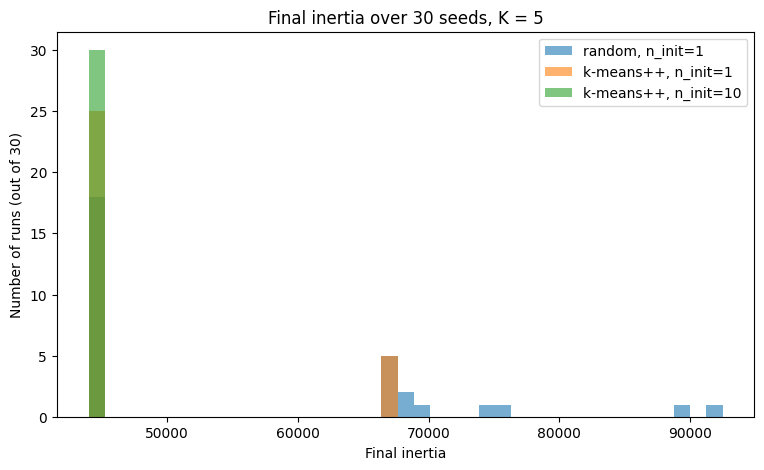

In [16]:
settings = {
    'random, n_init=1':      dict(init='random',    n_init=1),
    'k-means++, n_init=1':   dict(init='k-means++', n_init=1),
    'k-means++, n_init=10':  dict(init='k-means++', n_init=10),
}

results = {}
for name, kw in settings.items():
    results[name] = np.array([KMeans(n_clusters=5, random_state=s, **kw).fit(X2).inertia_
                              for s in range(30)])

best = round(min(v.min() for v in results.values()), 1)   # overall best inertia

rows = []
for name, v in results.items():
    r = np.round(v, 1)
    rows.append([name, len(np.unique(r)), v.min(), v.max(), 100 * np.mean(r == best)])
table = pd.DataFrame(rows, columns=['Setting', 'Distinct inertias', 'Lowest', 'Highest', '% runs at best'])
print(table.round(2).to_string(index=False))

plt.figure(figsize=(9, 5))
bins = np.linspace(44000, 92500, 40)
for name, v in results.items():
    plt.hist(v, bins=bins, alpha=0.6, label=name)
plt.xlabel('Final inertia'); plt.ylabel('Number of runs (out of 30)')
plt.title('Final inertia over 30 seeds, K = 5'); plt.legend()
plt.show()


### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


             Setting  Distinct inertias   Lowest  Highest  % runs at best
    random, n_init=1                 14 44448.46 91761.98           33.33
 k-means++, n_init=1                  6 44448.46 66733.44           60.00
k-means++, n_init=10                  1 44448.46 44448.46          100.00


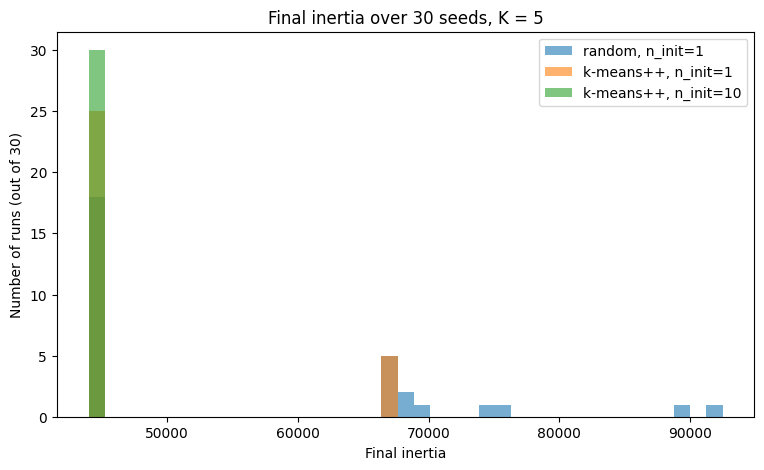

In [17]:
settings = {
    'random, n_init=1':      dict(init='random',    n_init=1),
    'k-means++, n_init=1':   dict(init='k-means++', n_init=1),
    'k-means++, n_init=10':  dict(init='k-means++', n_init=10),
}

results = {}
for name, kw in settings.items():
    results[name] = np.array([KMeans(n_clusters=5, random_state=s, **kw).fit(X2).inertia_
                              for s in range(30)])

best = round(min(v.min() for v in results.values()), 1)

rows = []
for name, v in results.items():
    r = np.round(v, 1)
    rows.append([name, len(np.unique(r)), v.min(), v.max(), 100 * np.mean(r == best)])
table = pd.DataFrame(rows, columns=['Setting', 'Distinct inertias', 'Lowest', 'Highest', '% runs at best'])
print(table.round(2).to_string(index=False))

plt.figure(figsize=(9, 5))
bins = np.linspace(44000, 92500, 40)
for name, v in results.items():
    plt.hist(v, bins=bins, alpha=0.6, label=name)
plt.xlabel('Final inertia'); plt.ylabel('Number of runs (out of 30)')
plt.title('Final inertia over 30 seeds, K = 5'); plt.legend()
plt.show()


**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



(a) The random-start setting (init='random', n_init=1) produced 14 different final inertia values over the 30 runs, and only 33.3% of the runs (10 out of 30) reached the best inertia, 44,448.46. Its worst run ended at 91,761.98, about double the best. k-means++ with n_init=1 produced only 6 different values, and 60% of its runs reached the best. k-means++ with n_init=10 produced just 1 value, and 100% of its runs reached the best.

(b) K-Means only improves the answer step by step from its starting centroids, and it stops at the first point where nothing improves. That point is a local minimum, not always the best possible solution. Different starting centroids can lead to different local minima. In my experiment the random starts ended in 14 different solutions with inertia from 44,448 to 91,762, even though the data and K = 5 were the same. In the worst run (seed 13), one big cluster of 119 customers merged several groups, while the high-income area was split into 4 small clusters.

(c) k-means++ chooses starting centroids that are far from each other, so it is less likely to start with two centroids inside the same group. This raised the share of runs reaching the best result from 33.3% to 60%, and it cut the worst inertia from 91,762 to 66,733. n_init runs K-Means several times from different starts and keeps the run with the lowest inertia. With n_init=10, all 30 seeds gave the same inertia, 44,448.46, so the number of distinct values was 1 and 100% of the runs were best. Together they make the result stable and reliable.

(d) Cluster numbers are arbitrary names. The same grouping can be called cluster 0, 1, 2 in one run and cluster 4, 2, 0 in another, so comparing the label numbers directly would call identical clusterings different. ARI compares which pairs of customers are grouped together, not the numbers. It gives 1 for the same grouping and about 0 for random agreement, whatever the numbering. For example, my best and worst runs had an ARI of only 0.455, which shows how different they really were.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI raw k$     vs raw dollars    : 0.4897
ARI scaled k$  vs scaled dollars : 1.0
ARI raw dollars vs scaled dollars: 0.3605


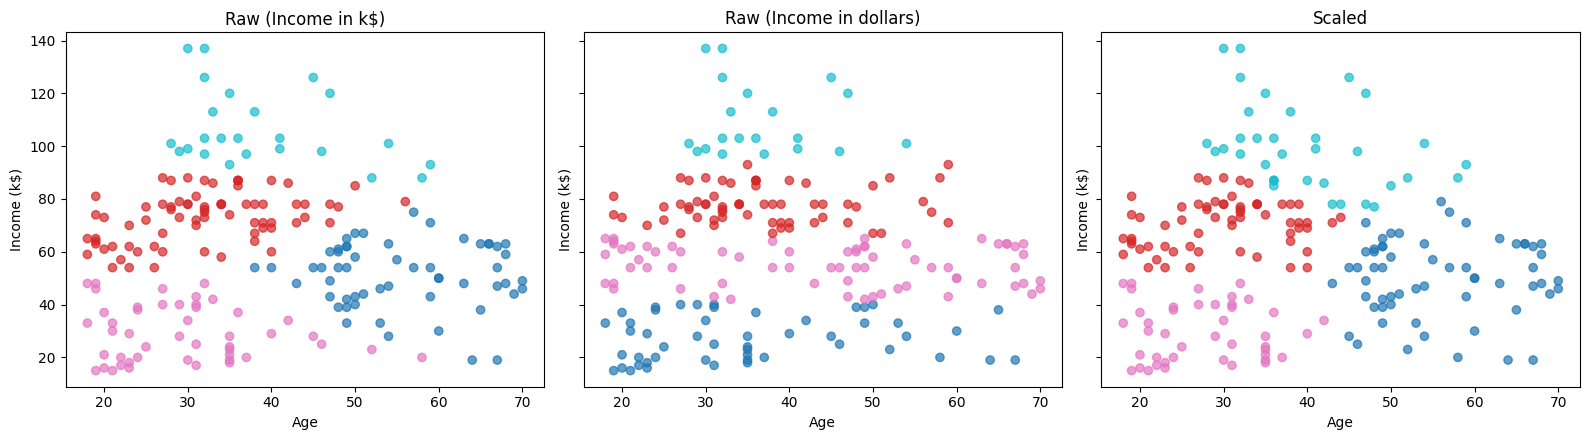

In [18]:
X_k = df[['Age', 'Income']].values.astype(float)
X_d = X_k.copy(); X_d[:, 1] = X_d[:, 1] * 1000

def fit_labels(X):
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

lab_raw_k = fit_labels(X_k)
lab_raw_d = fit_labels(X_d)
lab_sc_k  = fit_labels(StandardScaler().fit_transform(X_k))
lab_sc_d  = fit_labels(StandardScaler().fit_transform(X_d))

print("ARI raw k$     vs raw dollars    :", round(adjusted_rand_score(lab_raw_k, lab_raw_d), 4))
print("ARI scaled k$  vs scaled dollars :", round(adjusted_rand_score(lab_sc_k, lab_sc_d), 4))
print("ARI raw dollars vs scaled dollars:", round(adjusted_rand_score(lab_raw_d, lab_sc_d), 4))


fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for a, lab, title in [(ax[0], lab_raw_k, 'Raw (Income in k$)'),
                      (ax[1], lab_raw_d, 'Raw (Income in dollars)'),
                      (ax[2], lab_sc_k,  'Scaled')]:
    a.scatter(X_k[:, 0], X_k[:, 1], c=lab, cmap='tab10', alpha=0.7)
    a.set_xlabel('Age'); a.set_ylabel('Income (k$)'); a.set_title(title)
plt.tight_layout(); plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [19]:
wine = load_wine()
Xw, yw = wine.data, wine.target
print("Shape:", Xw.shape, "| true cultivar sizes:", np.bincount(yw))

sd = pd.Series(Xw.std(axis=0), index=wine.feature_names).sort_values(ascending=False)
print("\nThree largest std:\n", sd.head(3).round(3))
print("\nSmallest std:\n", sd.tail(1).round(4))


Shape: (178, 13) | true cultivar sizes: [59 71 48]

Three largest std:
 proline              314.022
magnesium             14.242
alcalinity_of_ash      3.330
dtype: float64

Smallest std:
 nonflavanoid_phenols    0.1241
dtype: float64


In [20]:
Xw_s = StandardScaler().fit_transform(Xw)

for name, D in [('Raw', Xw), ('Scaled', Xw_s)]:
    lab = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(D).labels_
    print(f"{name:7s} ARI = {adjusted_rand_score(yw, lab):.4f} | "
          f"Silhouette = {silhouette_score(D, lab):.4f} | Sizes = {np.bincount(lab)}")


Raw     ARI = 0.3711 | Silhouette = 0.5711 | Sizes = [62 47 69]
Scaled  ARI = 0.8975 | Silhouette = 0.2849 | Sizes = [65 51 62]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


Explained variance: [0.362 0.192] | total = 0.554


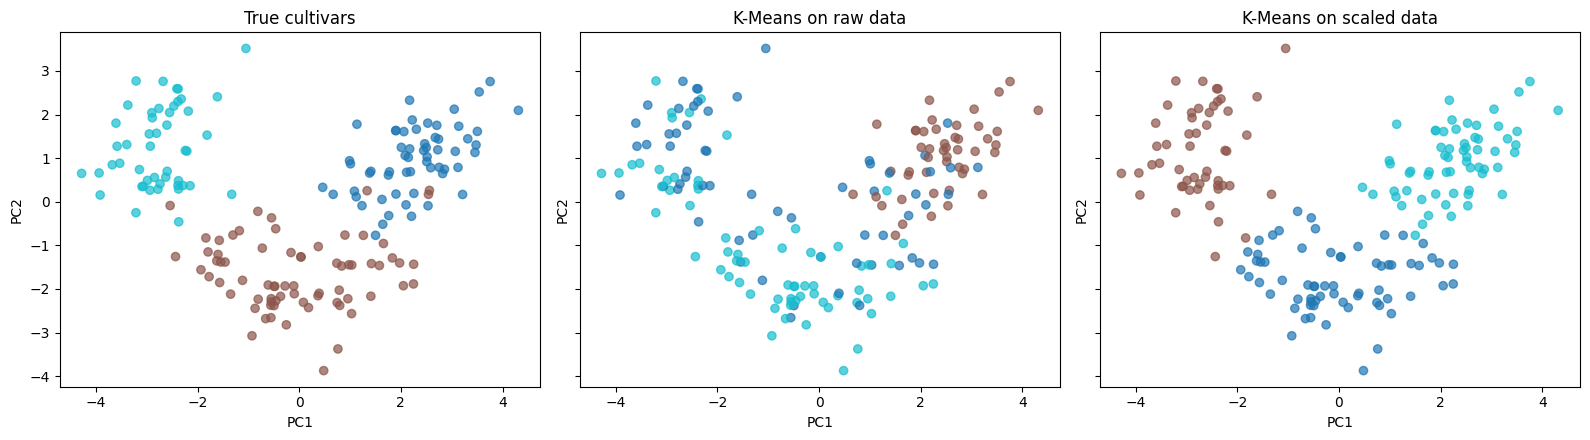

In [21]:
lab_raw    = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw).labels_
lab_scaled = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xw_s).labels_

pca = PCA(n_components=2, random_state=SEED).fit(Xw_s)
Z = pca.transform(Xw_s)
print("Explained variance:", pca.explained_variance_ratio_.round(3),
      "| total =", pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for a, lab, title in [(ax[0], yw,         'True cultivars'),
                      (ax[1], lab_raw,    'K-Means on raw data'),
                      (ax[2], lab_scaled, 'K-Means on scaled data')]:
    a.scatter(Z[:, 0], Z[:, 1], c=lab, cmap='tab10', alpha=0.7)
    a.set_xlabel('PC1'); a.set_ylabel('PC2'); a.set_title(title)
plt.tight_layout(); plt.show()


**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



(a) When Income was changed from k$ to dollars (15 to 137 became 15,000 to 137,000), the ARI between the two raw clusterings was only 0.490, so about half of the customers’ grouping changed, although the data was the same. The distance is d = √((ΔAge)² + (ΔIncome)²). Age differences are at most about 52 years (18 to 70), so (ΔAge)² is at most about 2,700. An Income difference of just 10,000 dollars gives (ΔIncome)² = 100,000,000. So Income controls the distance and Age is almost ignored. The clusters become Income bands (centroid incomes about 27,400, 54,765, 77,807 and 109,700), with similar Age everywhere (about 35 to 44). After scaling, both versions gave the same clusters (ARI = 1.0), because StandardScaler removes the unit.

(b) proline dominated the raw distance. Its standard deviation is 314.02, compared with magnesium 14.24, alcalinity_of_ash 3.33 and the smallest, nonflavanoid_phenols 0.124. Proline’s spread is about 2,500 times that of the smallest feature, so differences in proline decide almost every raw distance. The ARI against the true cultivar was 0.371 for raw data and 0.898 for scaled data.

(c) Silhouette measures only how compact and separated the clusters are in the space where the clustering was done. It does not know the true groups. On raw data, proline stretches the data along one axis, so the points form wide, well-separated bands in proline. That gives a high silhouette (0.571), even though those bands do not match the cultivars (ARI 0.371). On scaled data all 13 features contribute, the real groups overlap more in that 13-dimensional space, and the silhouette is lower (0.285), though the clustering is much better (ARI 0.898). Comparing the two silhouettes is not fair, because the distances are measured in different spaces with different scales. A high silhouette only means “clear separation in this one feature space”, not “correct groups”.

(d) My rule is to scale whenever the features have different units or very different ranges (check the standard deviations), unless all features are already on the same scale and meaningful, because otherwise the feature with the biggest numbers decides the clusters. Then I check that the clusters make sense, for example by profiling them, rather than relying on the silhouette across scaled and unscaled versions.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [22]:
X_out = np.vstack([X2, [400, 99]])

km_orig = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_out  = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_out)

def show(km, name):
    order = np.argsort(km.cluster_centers_[:, 0])
    print(f"{name}\n sizes   :", np.bincount(km.labels_)[order])
    print(" centroids (Income, Spending):\n", km.cluster_centers_[order].round(1), "\n")

show(km_orig, "Original (200 customers)")
show(km_out,  "With extra customer (201)")

print("ARI (200 customers):", round(adjusted_rand_score(km_orig.labels_, km_out.labels_[:200]), 4))


Original (200 customers)
 sizes   : [22 23 81 39 35]
 centroids (Income, Spending):
 [[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]] 

With extra customer (201)
 sizes   : [ 23 100  39  38   1]
 centroids (Income, Spending):
 [[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]] 

ARI (200 customers): 0.7532


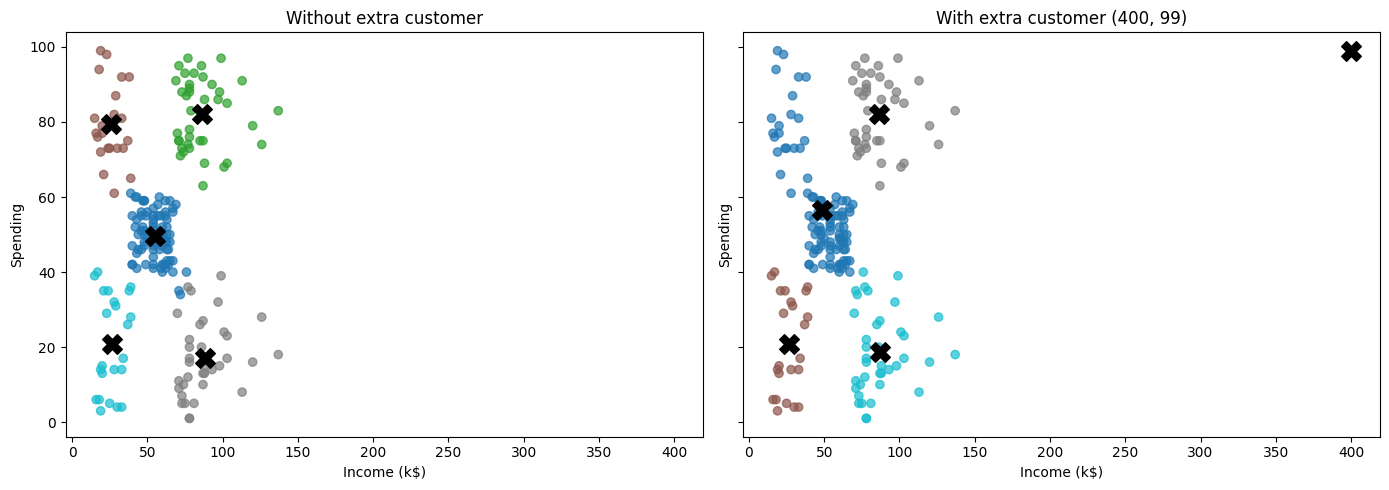

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
ax[0].scatter(X2[:, 0], X2[:, 1], c=km_orig.labels_, cmap='tab10', alpha=0.7)
ax[0].scatter(*km_orig.cluster_centers_.T, c='black', marker='X', s=200)
ax[0].set_title('Without extra customer')

ax[1].scatter(X_out[:, 0], X_out[:, 1], c=km_out.labels_, cmap='tab10', alpha=0.7)
ax[1].scatter(*km_out.cluster_centers_.T, c='black', marker='X', s=200)
ax[1].set_title('With extra customer (400, 99)')
for a in ax: a.set_xlabel('Income (k$)'); a.set_ylabel('Spending')
plt.tight_layout(); plt.show()


### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


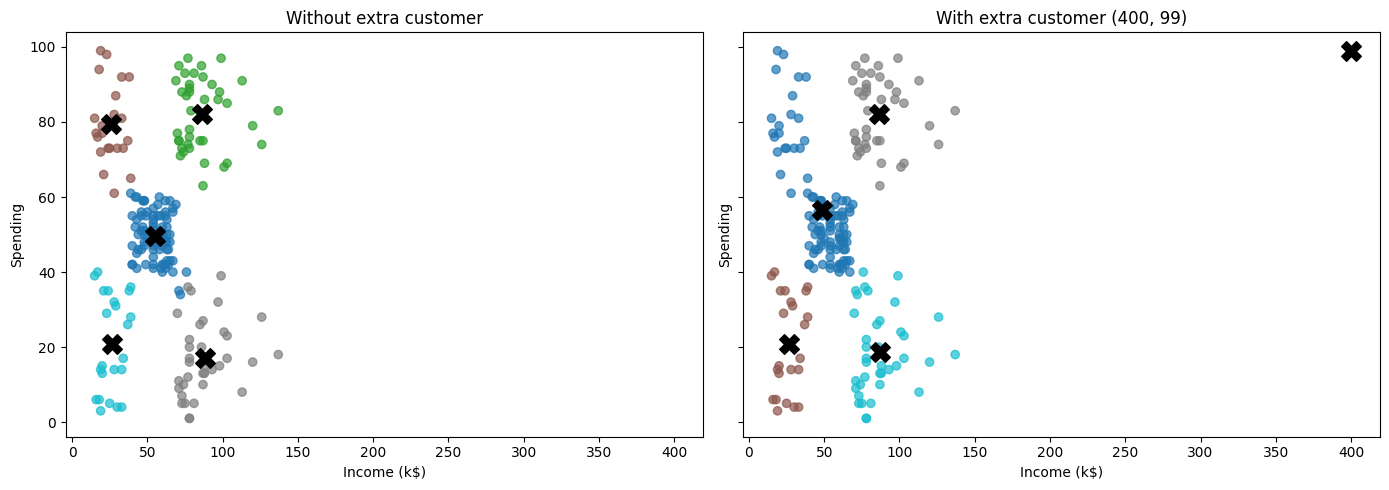

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
ax[0].scatter(X2[:, 0], X2[:, 1], c=km_orig.labels_, cmap='tab10', alpha=0.7)
ax[0].scatter(*km_orig.cluster_centers_.T, c='black', marker='X', s=200)
ax[0].set_title('Without extra customer')

ax[1].scatter(X_out[:, 0], X_out[:, 1], c=km_out.labels_, cmap='tab10', alpha=0.7)
ax[1].scatter(*km_out.cluster_centers_.T, c='black', marker='X', s=200)
ax[1].set_title('With extra customer (400, 99)')
for a in ax: a.set_xlabel('Income (k$)'); a.set_ylabel('Spending')
plt.tight_layout(); plt.show()


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



(a) The single extreme customer (Income 400, Spending 99) took one whole cluster for itself: it formed a cluster of 1 customer with centroid (400, 99). The other 200 customers then had to share only 4 clusters. The low-income / high-spending group (22 customers, centroid 25.7, 79.4) merged with the mid group (81 customers, centroid 55.3, 49.5) into one cluster of 100 customers (centroid 48.3, 56.5). The high-income / low-spending group moved from centroid (88.2, 17.1) to (87.0, 18.6) and its size changed from 35 to 38. The low/low group (26.3, 20.9) and the high/high group (86.5, 82.1) stayed almost the same. The ARI on the original 200 customers dropped to 0.753.

(b) The rule detected the extra customer clearly: its distance to the nearest centroid is 313.92, while the threshold (mean 13.02 + 3 × std 7.26) is only 34.80. The rule also flagged 4 real customers (IDs 197 to 200) with Income 126 to 137 and Spending 28, 74, 18 and 83. These are not data mistakes, because the values are normal. They are the highest-income customers in the data, so they are far from their cluster centres. They are worth a closer look as a possible small premium (VIP) group.

(c) Two ways: (1) remove the flagged points and refit (the ARI against the original model was then 0.985), or (2) keep them but reduce their effect (cap or transform the value, use a robust method such as K-Medoids, or treat them as a separate “special customers” group). The risk of simply deleting them is losing real and possibly valuable customers, like these 4 high spenders, so the business never learns about them.


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [25]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
df['Cluster'] = km5.labels_
df['Female'] = (df['Gender'] == 'Female').astype(int)

profile = (df.groupby('Cluster')
             .agg(Customers=('CustomerID', 'count'), Age=('Age', 'mean'),
                  Income=('Income', 'mean'), Spending=('Spending', 'mean'),
                  PctFemale=('Female', 'mean'))
             .sort_values('Income'))
profile['PctFemale'] = profile['PctFemale'] * 100
print(profile.round(1))

         Customers   Age  Income  Spending  PctFemale
Cluster                                              
2               22  25.3    25.7      79.4       59.1
4               23  45.2    26.3      20.9       60.9
0               81  42.7    55.3      49.5       59.3
1               39  32.7    86.5      82.1       53.8
3               35  41.1    88.2      17.1       45.7


In [26]:
def level(v, low, high):
    return 'Low' if v < low else ('High' if v >= high else 'Mid')

names = profile.apply(lambda r: f"{level(r.Income, 40, 70)} income / {level(r.Spending, 35, 65)} spending", axis=1)
df['Segment'] = df['Cluster'].map(names)
print(df['Segment'].value_counts())

Segment
Mid income / Mid spending      81
High income / High spending    39
High income / Low spending     35
Low income / Low spending      23
Low income / High spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [27]:
print((df.groupby('Segment')['Female'].mean() * 100).round(1))
print("Overall % female:", round(df['Female'].mean() * 100, 1))

X3 = StandardScaler().fit_transform(df[['Age', 'Income', 'Spending']])
for k in range(2, 9):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X3)
    print(k, round(silhouette_score(X3, lab), 4))


Segment
High income / High spending    53.8
High income / Low spending     45.7
Low income / High spending     59.1
Low income / Low spending      60.9
Mid income / Mid spending      59.3
Name: Female, dtype: float64
Overall % female: 56.0
2 0.3355
3 0.3578
4 0.404
5 0.4166
6 0.4284
7 0.4172
8 0.4082


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [28]:
km3 = KMeans(n_clusters=6, n_init=10, random_state=SEED).fit(X3)
df['Cluster3'] = km3.labels_

profile3 = (df.groupby('Cluster3')
              .agg(Customers=('CustomerID', 'count'), Age=('Age', 'mean'),
                   Income=('Income', 'mean'), Spending=('Spending', 'mean'))
              .sort_values('Age'))
print(profile3.round(1))
print("ARI (3-feature vs 2-feature):", round(adjusted_rand_score(df['Cluster'], df['Cluster3']), 4))


          Customers   Age  Income  Spending
Cluster3                                   
4                23  25.0    25.3      77.6
1                39  26.8    57.1      48.1
3                39  32.7    86.5      82.1
2                33  41.9    88.9      17.0
5                21  45.5    26.3      19.4
0                45  56.3    54.3      49.1
ARI (3-feature vs 2-feature): 0.7002


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)





(b) The most valuable segment now is VIP Big Spenders (39 customers). They have a high income (86.5) and the highest spending score (82.1), so they bring the most revenue at the moment. The biggest opportunity is Untapped Affluent (35 customers). Their income is just as high (88.2), but their spending score is only 17.1, about five times lower than the VIPs. They have the money but do not spend it here, so even moving them to a mid spending level would bring a large gain.

(c) Gender helps only a little. The overall share of women is 56.0%. By segment it is: Low income / Low spending 60.9%, Mid / Mid 59.3%, Low income / High spending 59.1%, High / High 53.8% and High income / Low spending 45.7%. Four of the five segments are within about 3 to 5 points of the overall 56.0%. Only High income / Low spending has a male majority (54.3% male), and that is a small difference. So Income and Spending separate the segments, not Gender.

(d) Yes, Age changes part of the story. With scaled Age, Income and Spending, the best K by silhouette was 6 (0.4284), and the ARI with the 2-feature K = 5 segmentation is 0.700, so the two results agree on a lot but not everything. The VIP group stays the same (39 customers, Age 32.7, Income 86.5, Spending 82.1). The main new finding is that the mid group splits by age: one group is young (Age 26.8, 39 customers) and the other is older (Age 56.3, 45 customers), both with Income about 55 and Spending about 49. The low/low group is older (Age 45.5, 21 customers) and the high income / low spending group has Age 41.9 (33 customers).

I would present the 2-feature K = 5 segmentation. It is simpler, it matches the 5 clear groups in the Income vs Spending plot, and each segment maps directly to a business action. I would use Age as an extra column in the profile to adjust the tone and channel of each message, for example social media for the 25-year-old trend spenders. I would not choose between the two segmentations by silhouette, since 0.5539 (2 features) and 0.4284 (3 features) are measured in different feature spaces and cannot be compared directly.

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [ ]:
out = df[['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']]
out.to_csv('customer_segments.csv', index=False)

print("Saved: customer_segments.csv |", out.shape[0], "rows")
print(out['Segment'].value_counts())
out.head()


**Executive Summary** (6-8 lines)

*Your summary here.*


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



(a) The most surprising result was that the silhouette was higher on the raw Wine data (0.571) than on the scaled data (0.285), although the raw clustering was much worse (ARI 0.371 versus 0.898). A second surprise was that a single extra customer changed the clusters so much: the ARI on the original 200 customers fell to 0.753, and two real groups merged into one cluster of 100 customers.

(b) With one more hour I would (1) try a method that does not need round clusters and handles outliers, such as DBSCAN or a Gaussian Mixture model, and compare it with K-Means using stability checks (for example, ARI across bootstrap samples); (2) test the 6-cluster solution with Age more closely, since it split the mid group into a young and an older customer group; and (3) turn the segments into a small dashboard or a simple rule that assigns a new customer to a segment, so the marketing team can use it without running the notebook.

---